In [16]:
import Pkg; Pkg.add("LambertW")
import Pkg; Pkg.add("QuadGK")

   Resolving package versions...
  No Changes to `~/.julia/environments/v1.11/Project.toml`
  No Changes to `~/.julia/environments/v1.11/Manifest.toml`
   Resolving package versions...
  No Changes to `~/.julia/environments/v1.11/Project.toml`
  No Changes to `~/.julia/environments/v1.11/Manifest.toml`


### 0. Defining constants and functions

In [17]:
using LinearAlgebra
using Plots
using LambertW
using Distributions
using Statistics
using QuadGK

# Constants for Re=2500 in the ONERA tunnel (H. Kahalerras, Y. Malécot, Y. Gagne, B. Castaing, Intermittency and Reynolds number, Phys. Fluids 10 (1998))
#c1 = 0.37

c2 = 0.025
c1 = 1/3 + 3/2 * c2
L = 0.0302    #(in m)
σ = 1.0      #(in m^2/s^2)

1.0

In [18]:
# Function
f(h, l, x) = -log(l/L) * ((h - c1)^2 / (2*c2) - h) + 0.5 * (x/σ)^2 * (l/L)^(-2h)

# First derivative f'(h, l, x) selon h
fprime(h, l, x) = -log(l/L) * ((h - c1)/(c2) - 1 + (x/σ)^2 * (l/L)^(-2h))

# Second derivative f''(h, l, x) selon h
fsecond(h, l, x) = -log(l/L) * (1/(c2) - 2 * (x/σ)^2 * log(l/L) * (l/L)^(-2h))

fsecond (generic function with 1 method)

### 1. Normalized PDF computed with QuadGK

##### a. P_{δ_ℓu}(x) and log(P_{δ_ℓu}(x))

In [19]:
normalization_term(l) = sqrt(σ^2 * (l/L)^(2*(c1-c2)))
#normalization_term(l) = sqrt((l/L)^(2/3))

function safe_integrand_pdf(h, l, x)
    val = exp(-f(h,l,x))
    return isfinite(val) ? val : 0.0
end

function compute_P_δlu_of_x(l, x)
    prefactor = (1 / (2π*σ)) * sqrt(-log(l/L) / c2)

    integral, err = quadgk(
        h -> safe_integrand_pdf(h,l,x),
        -Inf, Inf;
    )

    return prefactor * integral
end

function compute_P_δlv_of_x(l, x)
    return normalization_term(l) * compute_P_δlu_of_x(l, normalization_term(l)*x)
end

compute_P_δlv_of_x (generic function with 1 method)

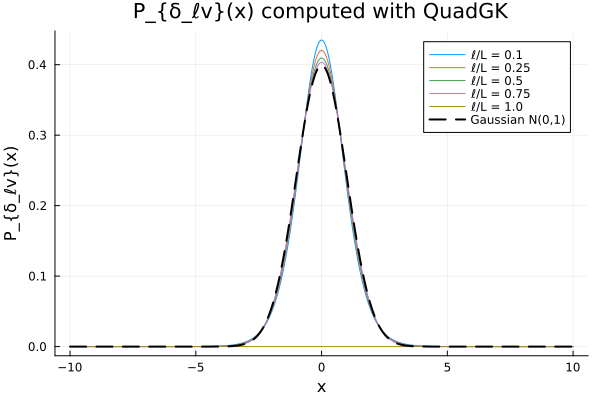

In [ ]:
# Define l values
l_values = 1e-4:0.01*L:L

# Define x values
x_values = -10:0.01:10

# Create the plot for P_{δlu}(x)
p1 = plot(title = "P_{δ_ℓv}(x) computed with QuadGK",
          xlabel = "x",
          ylabel = "P_{δ_ℓv}(x)",
          lw = 2)

# Loop over each l and plot the corresponding density
for l in l_values
    P_values = [compute_P_δlv_of_x(l, x) for x in x_values]
    plot!(p1, x_values, P_values, label = "ℓ/L = $(round(l/L, digits=2))")
end

# Add standard Gaussian for reference
gauss = Normal(0, 1)
P_gauss = pdf.(gauss, x_values)
plot!(p1, x_values, P_gauss, label = "Gaussian N(0,1)", lw = 2, ls = :dash, color = :black)

# Display the final plot
display(p1)


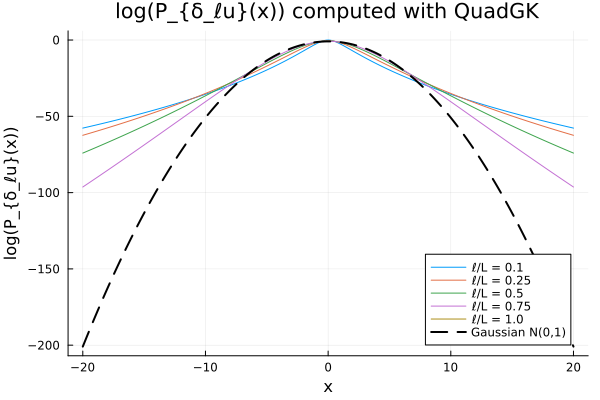

In [ ]:
# Define l values
l_values = 1e-4:0.01*L:L

# Define x values
x_values = -20:0.01:20

# Create the plot for log(P_{δlu}(x))
p1 = plot(title = "log(P_{δ_ℓu}(x)) computed with QuadGK",
          xlabel = "x",
          ylabel = "log(P_{δ_ℓu}(x))",
          lw = 2)

# Loop over each l and plot log(P_{δlu}(x))
for l in l_values
    P_values = [compute_P_δlu_of_x(l, x) for x in x_values]
    log_P_values = [log(P) for P in P_values if P > 0]  # avoid log(0)
    valid_x = [x for (x, P) in zip(x_values, P_values) if P > 0]
    plot!(p1, valid_x, log_P_values, label = "ℓ/L = $(round(l/L, digits=2))")
end

# Add standard Gaussian for reference
gauss = Normal(0, 1)
P_gauss = pdf.(gauss, x_values)
logP_gauss = log.(P_gauss)
plot!(p1, x_values, logP_gauss, label = "Gaussian N(0,1)", lw = 2, ls = :dash, color = :black)

# Display the final plot
display(p1)


##### b. Entropy

In [22]:
function safe_integrand_entropy(p_function,l,x)
    p = p_function(l, x)
    val = -p * log(p)
    return isfinite(val) ? val : 0.0
end

function compute_entropy_for_l(p_function,l)
    entropy, err = quadgk(
        x -> safe_integrand_entropy(p_function,l,x),
        -Inf, Inf;
    )
    return entropy
end

compute_entropy_for_l (generic function with 1 method)

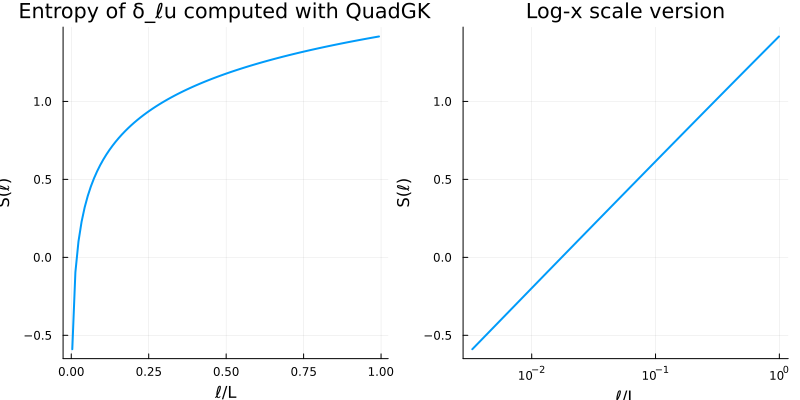

In [23]:
# Define l values
l_values = 1e-4:0.01*L:L
S_values = [compute_entropy_for_l(compute_P_δlu_of_x,l) for l in l_values]

# Create the plot for S(l)
p1 = plot(l_values./L, S_values,
          title = "Entropy of δ_ℓu computed with QuadGK",
          xlabel = "ℓ/L",
          ylabel = "S(ℓ)",
          lw = 2,
          legend = false)

p2 = plot(l_values./L, S_values,
          title = "Log-x scale version",
          xlabel = "ℓ/L",
          ylabel = "S(ℓ)",
          xscale = :log10,
          lw = 2,
          legend = false)

# Plot
plot(p1, p2, layout = (1, 2), size = (800, 400))

### 2. Normalized PDF, h*=c_1 (Laplace approximation)

##### a. P_{δ_ℓu}(x) and log(P_{δ_ℓu}(x))

In [24]:
# Value of h_star
h_star(l, x) = c1

h_star (generic function with 1 method)

In [25]:
function compute_P_δlu_of_x_Laplace(l, x; tol=1e-10, maxiter=100)
    # Asserts the validity of the Laplace point (f'' must be < 0)
    if fsecond(h_star(l, x), l, x) <= 0 || isnan(fsecond(h_star(l, x), l, x))
        return 0.0
    end

    prefactor = (1 / (sqrt(2π) * σ)) * sqrt((-log(l/L)) / c2) * sqrt(1 / (fsecond(h_star(l, x), l, x)))
    exponent = -f(h_star(l, x), l, x)

    exponent = clamp(exponent, -700, 700)
    return prefactor * exp(exponent)
end

compute_P_δlu_of_x_Laplace (generic function with 1 method)

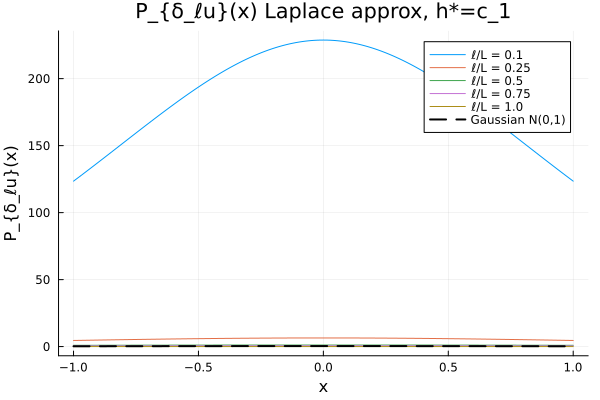

In [ ]:
# Define l values
l_values = 1e-4:0.01*L:L

# Define x values
x_values = -1:0.01:1

# Create the plot for P_{δlu}(x)
p1 = plot(title = "P_{δ_ℓu}(x) Laplace approx, h*=c_1",
          xlabel = "x",
          ylabel = "P_{δ_ℓu}(x)",
          lw = 2)

# Loop over each l and plot the corresponding density
for l in l_values
    P_values = [compute_P_δlu_of_x_Laplace(l, x) for x in x_values]
    plot!(p1, x_values, P_values, label = "ℓ/L = $(round(l/L, digits=2))")
end

# Add standard Gaussian for reference
gauss = Normal(0, 1)
P_gauss = pdf.(gauss, x_values)
plot!(p1, x_values, P_gauss, label = "Gaussian N(0,1)", lw = 2, ls = :dash, color = :black)

# Display the final plot
display(p1)


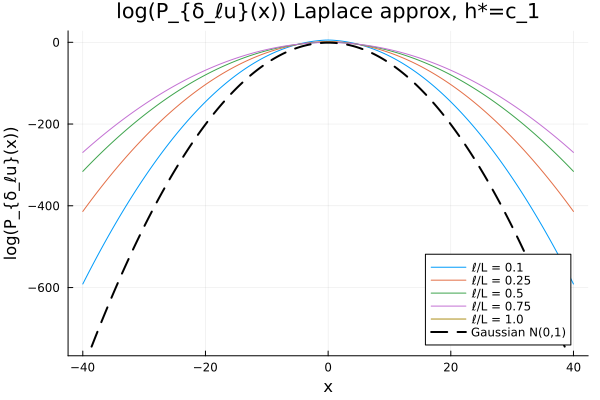

In [ ]:
# Define l values
l_values = 1e-4:0.01*L:L

# Define x values
x_values = -40:0.01:40

# Create the plot for log(P_{δlu}(x))
p1 = plot(title = "log(P_{δ_ℓu}(x)) Laplace approx, h*=c_1",
          xlabel = "x",
          ylabel = "log(P_{δ_ℓu}(x))",
          lw = 2)

# Loop over each l and plot log(P_{δlu}(x))
for l in l_values
    P_values = [compute_P_δlu_of_x_Laplace(l, x) for x in x_values]
    log_P_values = [log(P) for P in P_values if P > 0]  # avoid log(0)
    valid_x = [x for (x, P) in zip(x_values, P_values) if P > 0]
    plot!(p1, valid_x, log_P_values, label = "ℓ/L = $(round(l/L, digits=2))")
end

# Add standard Gaussian for reference
gauss = Normal(0, 1)
P_gauss = pdf.(gauss, x_values)
logP_gauss = log.(P_gauss)
plot!(p1, x_values, logP_gauss, label = "Gaussian N(0,1)", lw = 2, ls = :dash, color = :black)

# Display the final plot
display(p1)


##### b. Entropy

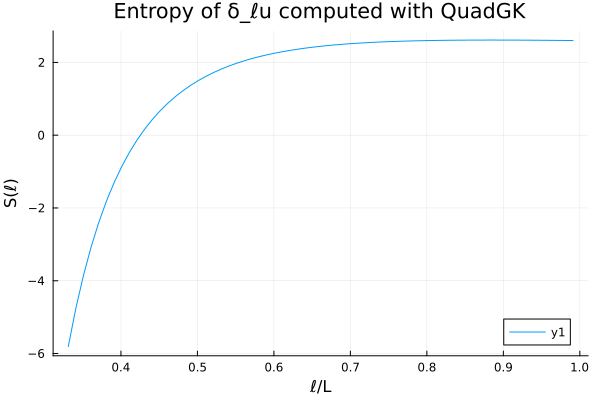

In [ ]:
# Define l values
l_values = 1e-4:0.01*L:L

# Create the plot for S(l)
p1 = plot(title = "Entropy of δ_ℓu computed with QuadGK",
          xlabel = "ℓ/L",
          ylabel = "S(ℓ)",
          lw = 2)

# Loop over each l and compute the entropies
S_values = [compute_entropy_for_l(compute_P_δlu_of_x_Laplace,l) for l in l_values]

# Plot
plot!(p1, l_values/L, S_values)
display(p1)

### 3. Normalized PDF, h* computed with Lambert W function (Laplace approximation)

##### a. P_{δ_ℓu}(x) and log(P_{δ_ℓu}(x))

In [37]:
# Value of h_star
using LambertW
h_star(l, x) = (c1 + c2) - lambertw(2 * c2 * abs(log(l / L)) * ((x / σ)^2) * ( (L^(c1+c2)) / l^(2*c1) )^2) / (2 * -log(l / L))

h_star (generic function with 1 method)

In [38]:
function compute_P_δlu_of_x_Laplace(l, x; tol=1e-10, maxiter=100)
    # Asserts the validity of the Laplace point (f'' must be < 0)
    if fsecond(h_star(l, x), l, x) <= 0 || isnan(fsecond(h_star(l, x), l, x))
        return 0.0
    end

    prefactor = (1 / (sqrt(2π) * σ)) * sqrt((-log(l/L)) / c2) * sqrt(1 / (fsecond(h_star(l, x), l, x)))
    exponent = -f(h_star(l, x), l, x)

    exponent = clamp(exponent, -700, 700)
    return prefactor * exp(exponent)
end

compute_P_δlu_of_x_Laplace (generic function with 1 method)

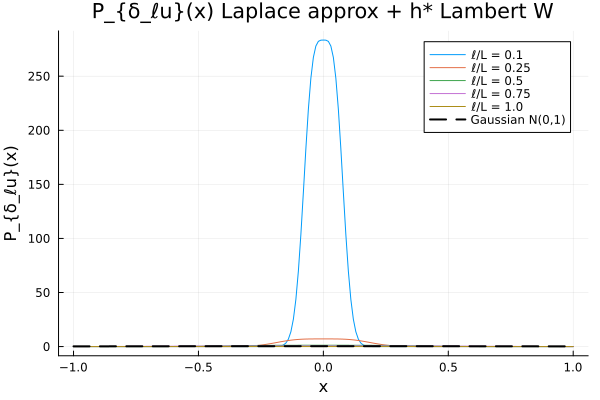

In [ ]:
# Define l values
l_values = 1e-4:0.01*L:L

# Define x values
x_values = -1:0.01:1

# Create the plot for P_{δlu}(x)
p1 = plot(title = "P_{δ_ℓu}(x) Laplace approx + h* Lambert W",
          xlabel = "x",
          ylabel = "P_{δ_ℓu}(x)",
          lw = 2)

# Loop over each l and plot the corresponding density
for l in l_values
    P_values = [compute_P_δlu_of_x_Laplace(l, x) for x in x_values]
    plot!(p1, x_values, P_values, label = "ℓ/L = $(round(l/L, digits=2))")
end

# Add standard Gaussian for reference
gauss = Normal(0, 1)
P_gauss = pdf.(gauss, x_values)
plot!(p1, x_values, P_gauss, label = "Gaussian N(0,1)", lw = 2, ls = :dash, color = :black)

# Display the final plot
display(p1)


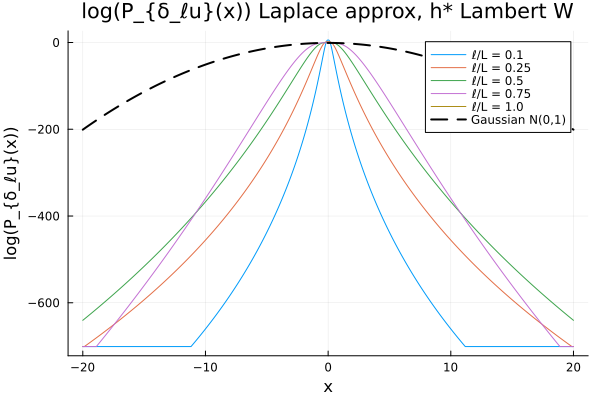

In [ ]:
# Define l values
l_values = 1e-4:0.01*L:L

# Define x values
x_values = -20:0.01:20

# Create the plot for log(P_{δlu}(x))
p1 = plot(title = "log(P_{δ_ℓu}(x)) Laplace approx, h* Lambert W",
          xlabel = "x",
          ylabel = "log(P_{δ_ℓu}(x))",
          lw = 2)

# Loop over each l and plot log(P_{δlu}(x))
for l in l_values
    P_values = [compute_P_δlu_of_x_Laplace(l, x) for x in x_values]
    log_P_values = [log(P) for P in P_values if P > 0]  # avoid log(0)
    valid_x = [x for (x, P) in zip(x_values, P_values) if P > 0]
    plot!(p1, valid_x, log_P_values, label = "ℓ/L = $(round(l/L, digits=2))")
end

# Add standard Gaussian for reference
gauss = Normal(0, 1)
P_gauss = pdf.(gauss, x_values)
logP_gauss = log.(P_gauss)
plot!(p1, x_values, logP_gauss, label = "Gaussian N(0,1)", lw = 2, ls = :dash, color = :black)

# Display the final plot
display(p1)


##### b. Entropy

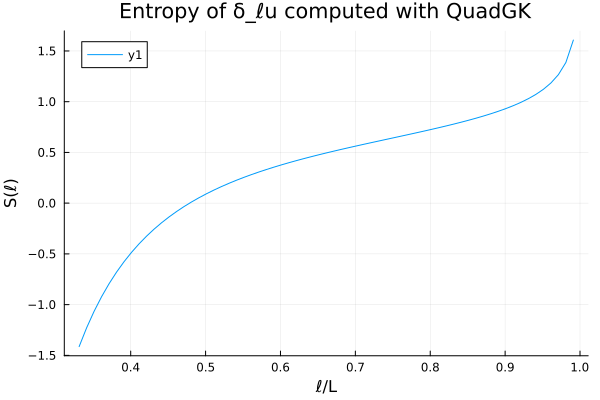

In [ ]:
# Define l values
l_values = 1e-4:0.01*L:L

# Create the plot for S(l)
p1 = plot(title = "Entropy of δ_ℓu computed with QuadGK",
          xlabel = "ℓ/L",
          ylabel = "S(ℓ)",
          lw = 2)

# Loop over each l and compute the entropies
S_values = [compute_entropy_for_l(compute_P_δlu_of_x_Laplace,l) for l in l_values]

# Plot
plot!(p1, l_values/L, S_values)
display(p1)

### 4. Second order structure function and flatness

In [42]:
# PDF model:
# pdf_fun = compute_P_δlu_of_x           # exact QuadGK version
# pdf_fun = compute_P_δlu_of_x_Laplace   # Laplace version (uncomment if needed)
pdf_fun = compute_P_δlu_norm_of_x_finite_h

# x-range 
x_min = -20
x_max = 20
x_step = 0.01
x_vals = x_min:x_step:x_max

# Allocate containers
S1 = Float64[]
S2 = Float64[]
S3 = Float64[]
S4 = Float64[]
Flatness = Float64[]

for l in l_values

    # Compute PDF( x | l )
    P_vals = [pdf_fun(l, x) for x in x_vals]

    # Normalisation check (optional)
    # println("Integral P = ", sum(P_vals) * x_step)

    # Structure functions
    S1_l = sum( x * P * x_step for (x,P) in zip(x_vals, P_vals) )

    S2_l = sum( (x^2) * P * x_step for (x,P) in zip(x_vals, P_vals) ) - S1_l^2

    S3_l = sum( (x^3) * P * x_step for (x,P) in zip(x_vals, P_vals) )
    S4_l = sum( (x^4) * P * x_step for (x,P) in zip(x_vals, P_vals) )

    push!(S1, S1_l)
    push!(S2, S2_l)
    push!(S3, S3_l)
    push!(S4, S4_l)

    push!(Flatness, S4_l / S2_l^2)   
end


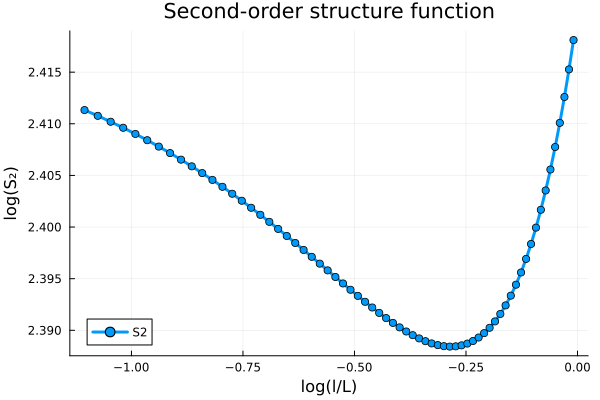

In [43]:
# S2 vs l
pS2 = plot(
    log.(l_values ./ L),
    log.(S2),
    xlabel = "log(l/L)",
    ylabel = "log(S₂)",
    lw = 3, marker = :circle,
    label="S2",
    title = "Second-order structure function"
)

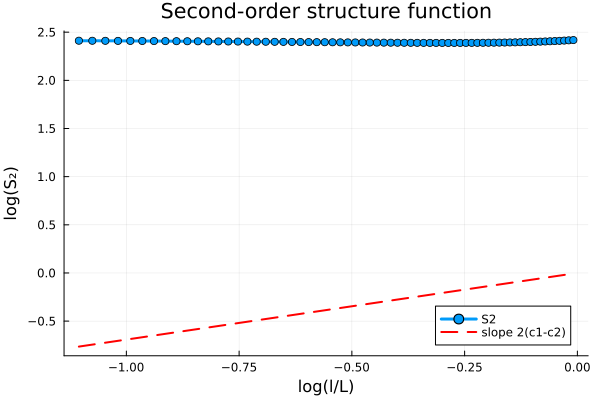

In [44]:
# theoretical slope 2(c1 - c2)
plot!(pS2, log.(l_values ./ L),
      2*(c1-c2)*log.(l_values ./ L),
      lw=2, ls=:dash, color=:red, label="slope 2(c1-c2)")

display(pS2)

┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/dVEMd/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/dVEMd/src/ticks.jl:194


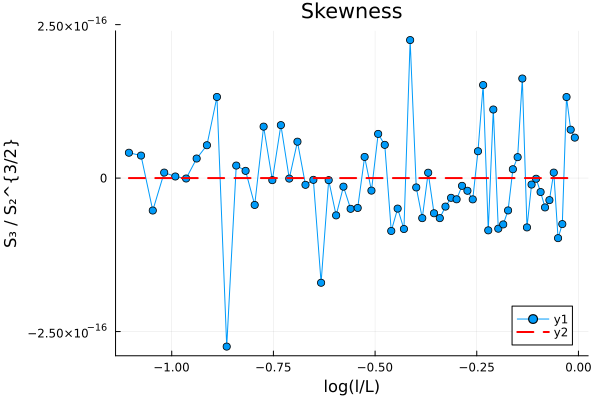

┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/dVEMd/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/dVEMd/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/dVEMd/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/dVEMd/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/dVEMd/src/ticks.jl:194


In [45]:
# Skewness S3/S2^(3/2)
pS3 = plot(
    log.(l_values ./ L),
    S3 ./ (S2 .^ (3/2)),
    xlabel="log(l/L)",
    ylabel="S₃ / S₂^{3/2}",
    marker=:circle,
    title="Skewness"
)
plot!(pS3, log.(l_values ./ L), zeros(length(l_values)), color=:red, lw=2, ls=:dash)

display(pS3)

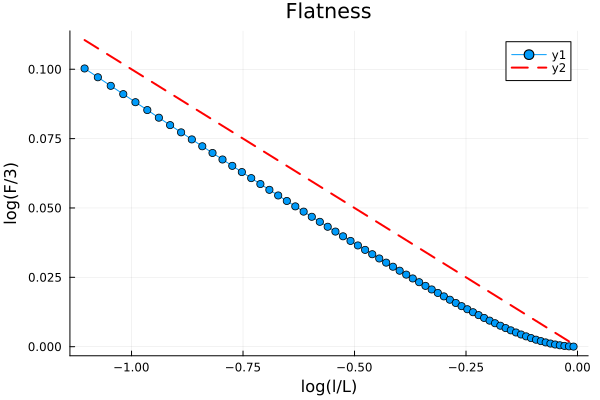

In [46]:
# Flatness F = S4/S2^2
pF = plot(
    log.(l_values ./ L),
    log.(Flatness ./ 3),     # optional scaling with 1/3
    xlabel="log(l/L)",
    ylabel="log(F/3)",
    marker=:circle,
    title="Flatness"
)

plot!(pF, log.(l_values ./ L),
      -0.1 .* log.(l_values ./ L), color=:red, lw=2, ls=:dash)

display(pF)